# Zona de habitabilidad alrededor de WASP-21

Ejercicio complementario: calcular los límites de la zona habitable (ZH) de la estrella anfitriona de WASP-21 b con las relaciones de [Kopparapu et al. (2013)](https://doi.org/10.1088/0004-637X/765/2/131) y compararlos con la órbita del planeta (≈ 0.05 UA).

> WASP-21 b es un Saturno caliente muy cercano a su estrella; este notebook es un ejercicio didáctico de modelado, **no** una afirmación de que el planeta sea habitable.

**Relaciones usadas**

Luminosidad y radio estelares aproximados (relaciones masa-luminosidad y masa-radio para $M_\star < 0.7\,M_\odot$ y $M_\star > 0.7\,M_\odot$):

$$ L \simeq \begin{cases} 0.20\,M^{2.50} & M<0.7 \\ 1.15\,M^{3.36} & M>0.7 \end{cases} \qquad R \simeq \begin{cases} 0.89\,M^{0.89} & M<1.66 \\ 1.01\,M^{0.57} & M>1.66 \end{cases} $$

Flujo estelar efectivo y distancia de la ZH, con $T_\star = T_{eff} - 5780\,\mathrm{K}$ y los coeficientes $S_{eff\odot},a,b,c,d$ de Kopparapu et al. (2013, Tabla 3):

$$ S_{eff} = S_{eff\odot} + aT_\star + bT_\star^2 + cT_\star^3 + dT_\star^4, \qquad d = \left(\frac{L/L_\odot}{S_{eff}}\right)^{0.5}\ \mathrm{AU} $$

In [ ]:
######ENTE################
import scipy.constants as sc
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import StrMethodFormatter, NullFormatter

#constantes (Zonas de habitabilidad para estrellas de baja masa y T(2600-7200K)) KOPPARAPU ET AL 2013 ERRATUM
              #Recent             Runaway       Moist       Maximum    Early
              #Venus            Greenhouse   Greenhouse  Greenhouse   Mars
S_effsol = np.array([1.7763,     1.0385,        1.0146,       0.3507,      0.3207])
a =        np.array([1.4335e-4,  1.2456e-4,     8.1884e-5,    5.9578e-5,   5.4471e-5])
b =        np.array([3.3954e-9,  1.4612e-8,     1.9394e-9,   1.6707e-9,   1.5275e-9])
c =        np.array([-7.6364e-12, -7.6345e-12, -4.3618e-12,-3.0058e-12, -2.1709e-12])
d =        np.array([-1.1950e-15, -1.7511e-15, -6.8260e-16, -5.1925e-16, -3.8282e-16])

csb = sc.Stefan_Boltzmann
sbc = csb /1.989e30 #constante de Stephan-Boltzmann U.C (Msol)

## 1. Modelo de baja masa: distancia de la ZH según la masa estelar

In [ ]:
M = 0.89  # masa de WASP-21 en masas solares (Chen)

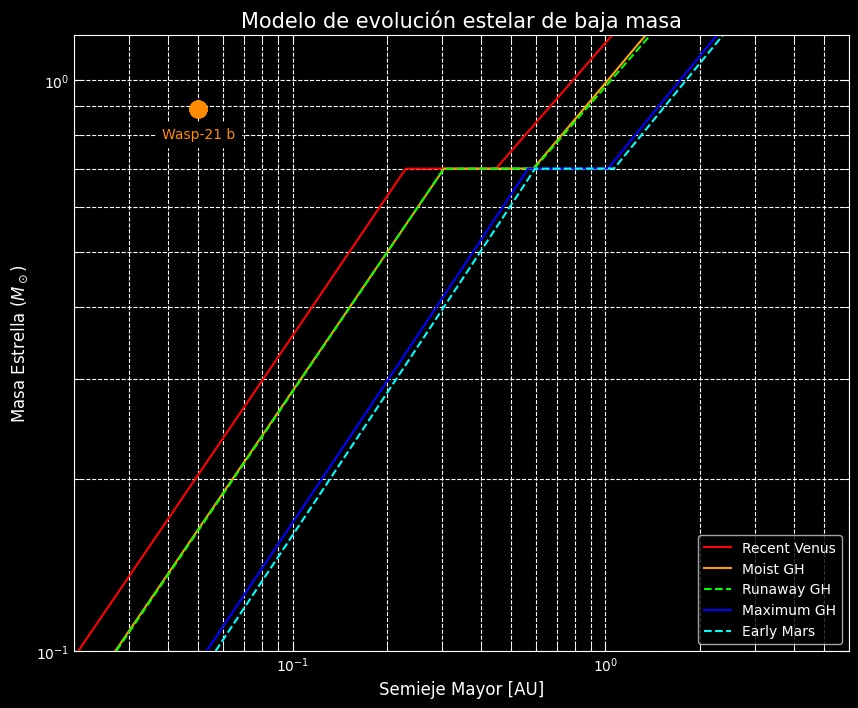

In [ ]:
import scipy.constants as sc
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter, NullFormatter


csb = sc.Stefan_Boltzmann

#funciones
def L(M): #M en masas solares
  if M < 0.7:
    Lum = (0.20)*(M**2.50)
  elif M > 0.7:
    Lum = (1.15)*(M**3.36)
  return Lum

def R(M):
  if M < 1.66:
    Radio = 0.89*(M**0.89)
  elif M > 1.66:
    Radio = 1.01*(M**0.57)
  return Radio

def T_eff(L,R):
  Lnueva = 3.828e26 * L
  Rnuevo = R * 6.96e8
  return (Lnueva/(4*np.pi*csb*Rnuevo**2))**(1/4); #K

def T_est(T_eff):
  return T_eff-5780; #K

def S_eff(S_effsol,a,b,c,d,T_est):
  return S_effsol +a*T_est+b*T_est**2+c*T_est**3+d*T_est**4; #W/m^2

#funcion definitiva (masa_estrella en función de la distancia de cada ZH)
def distancia_func(L,S_eff):
  d = (L/S_eff)**0.5
  return d

  plt.rcParams.update({'axes.titlesize': 13,'axes.labelsize': 13,
                     'legend.title_fontsize':10,'legend.fontsize':10})

#Ciclos para calcular los valores

etiquetas = ['Recent Venus', 'Moist GH','Runaway GH',
             'Maximum GH', 'Early Mars']

color = ["red","orange","lime","blue","cyan"]
ls = ["-","-","--","-","--"]

masas = np.linspace(0.1,1.2,5000)
fig, ax = plt.subplots(figsize = (10,8))
for i in range(5):

  distancias = np.zeros(5000)
  for j, masa in enumerate(masas):
    distancias[j] = distancia_func(L(masa),S_eff(S_effsol[i],a[i],b[i],c[i],d[i],T_est(T_eff(L(masa),R(masa)))))
  ax.loglog(distancias,masas, label = etiquetas[i],color=color[i],ls=ls[i])
  ax.loglog(0.05,M,"o",color="darkorange",ms=12)

ax.set_ylim([0.1,1.2])
ax.set_xlim([0.02,6])
ax.grid(axis = 'y', which = 'both',ls="--")
ax.grid(axis = 'x', which = 'both',ls="--")
ax.tick_params(axis = 'both', which = 'both', bottom=True, top=True, left=True, right=True, direction = 'in',length=6)
#plt.tick_params(axis='both', which='both', bottom=True, top=True, left=True, right=True, direction='in', length=6,grid_linestyle='--')
#plt.grid('x','both')

#Formatos para barras LogLog sin notación científica
# ax.xaxis.set_major_formatter(StrMethodFormatter('{x:.2f}'))
# ax.xaxis.set_minor_formatter(NullFormatter())
# ax.yaxis.set_major_formatter(StrMethodFormatter('{x:.2f}'))
# ax.yaxis.set_minor_formatter(StrMethodFormatter('{x:.2f}'))
plt.text(0.05, M-0.1, 'Wasp-21 b', color='darkorange', fontsize=10,backgroundcolor='k',ha='center')
ax.set_title(r'Modelo de evolución estelar de baja masa',fontsize = 15)
ax.set_ylabel(r'Masa Estrella ($M_\odot$)', fontsize = 12)
ax.set_xlabel('Semieje Mayor [AU]', fontsize = 12)
# leg = ax.legend(handlelength = 1.2)
# leg.get_frame().set_edgecolor('black')
ax.legend()
# plt.savefig('Modelo de Habitabilidad.pdf')
plt.show()

## 2. Límites de la ZH para WASP-21

In [ ]:
Ls = L(M)   # luminosidad de la estrella [L_sol]
Ls

In [ ]:
Teff=5800 #\\Chen
#Teff=5924 #\\TICv8
Ts=Teff-5780 #kelvin

def S_eff(a,b,c,d,Ssol,T=Ts):
  return Ssol + a*T+ b*T**2 + c*T**3+ d*T**4

def HZdist(Seff):
  return (Ls/Seff)**0.5 #UA

In [ ]:
Seff0 = float(S_eff(a[0],b[0],c[0],d[0],S_effsol[0]))
Seff1 = float(S_eff(a[1],b[1],c[1],d[1],S_effsol[1]))
Seff2 = float(S_eff(a[2],b[2],c[2],d[2],S_effsol[2]))
Seff3 = float(S_eff(a[3],b[3],c[3],d[3],S_effsol[3]))
Seff4 = float(S_eff(a[4],b[4],c[4],d[4],S_effsol[4]))

In [ ]:
RecVen=HZdist(Seff0)
Run=HZdist(Seff1)
Moist=HZdist(Seff2)
Max=HZdist(Seff3)
EaMar=HZdist(Seff4)

In [ ]:
RecVen,Run,Moist,Max,EaMar

(0.6610215462582582,
 0.8641704184406304,
 0.8746339404020964,
 1.4863439118237929,
 1.5543107485464331)

## 3. Visualización

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Wedge

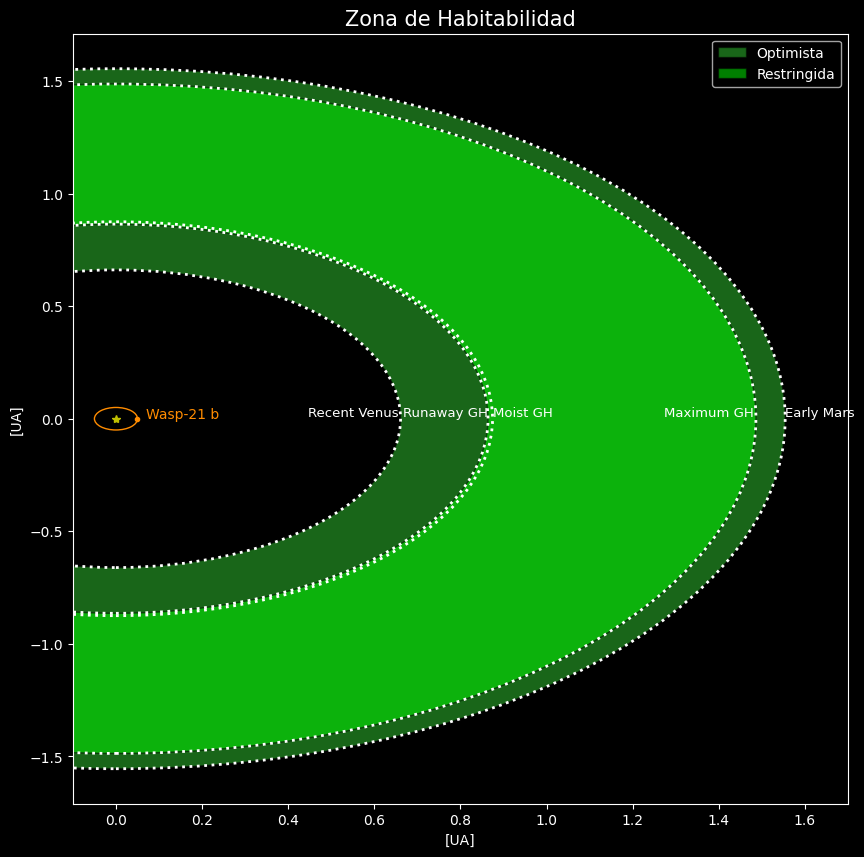

In [ ]:
fig = plt.figure(figsize=(10, 10))

# Crear la arandela
ring1 = Wedge((0,0), EaMar, 0, 360, width=EaMar-RecVen, facecolor='limegreen', edgecolor='black',alpha=0.5,label='Optimista')
ring2 = Wedge((0,0), Max, 0, 360, width=Max-Run, facecolor='lime', edgecolor='black',alpha=0.5,label='Restringida')
circle = plt.Circle((0, 0), 0.05, fill=False, linewidth=1, edgecolor='darkorange')
circle1 = plt.Circle((0, 0), RecVen, fill=False, linewidth=2, edgecolor='white',linestyle=':')
circle2 = plt.Circle((0, 0), Run, fill=False, linewidth=2, edgecolor='white',linestyle=':')
circle3 = plt.Circle((0, 0), Moist, fill=False, linewidth=2, edgecolor='white',linestyle=':')
circle4 = plt.Circle((0, 0), Max, fill=False, linewidth=2, edgecolor='white',linestyle=':')
circle5 = plt.Circle((0, 0), EaMar, fill=False, linewidth=2, edgecolor='white',linestyle=':')


# Agregar la arandela al eje
plt.gca().add_patch(ring1)
plt.gca().add_patch(ring2)
# Agregar los círculos al gráfico
plt.gca().add_patch(circle)
plt.gca().add_patch(circle1)
plt.gca().add_patch(circle2)
plt.gca().add_patch(circle3)
plt.gca().add_patch(circle4)
plt.gca().add_patch(circle5)


# Establecer los límites del eje
#plt.axis('scaled')
plt.xlim(-0.1, 1.7)
#ax.set_ylim(-1, 1)
# Mostrar el gráfico
plt.style.use('dark_background')
plt.plot(0,0,'y*')
plt.plot(0.05,0,'.',color='darkorange')
plt.title("Zona de Habitabilidad",fontsize=15)
plt.xlabel("[UA]",fontsize=10)
plt.ylabel("[UA]",fontsize=10)

plt.text(0.07, 0, 'Wasp-21 b', color='darkorange', fontsize=10)
plt.text( RecVen-0.11,0.01, 'Recent Venus', color='white',ha='center' ,fontsize=9.5)
plt.text( Run-0.1,0.01, 'Runaway GH', color='white',ha='center' ,fontsize=9.5)
plt.text( Moist+0.07,0.01, 'Moist GH', color='white',ha='center' ,fontsize=9.5)
plt.text( Max-0.11,0.01, 'Maximum GH', color='white',ha='center' ,fontsize=9.5)
plt.text( EaMar+0.08,0.01, 'Early Mars', color='white',ha='center' ,fontsize=9.5)

#plt.plot(1,0,'.',color='aqua')
plt.legend()
plt.show()